## 1. Libraries

In [27]:
import os, time, subprocess, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


## 2. Settings

In [28]:
QUICK = os.environ.get("CMAPSS_QUICK", "0") == "1"  # QUICK=1 is only for a short pipeline check
DATASET = os.environ.get("CMAPSS_DATASET", "FD001").upper()
if DATASET not in {"FD001", "FD002"}:
    raise ValueError("DATASET must be either 'FD001' or 'FD002'.")

DATA_DIR = os.environ.get(
    "CMAPSS_DIR",
    "/kaggle/input/datasets/tanmoypauldiat/cmapps-fd001-and-fd002"
)
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs_feature_selection"
os.makedirs(OUT_DIR, exist_ok=True)

SEED = 42
L = 50
RUL_CAP = 125
N_FOLDS = 5
TRAIN_STRIDE = 4
MIN_EVAL_CYCLE = 50

# FD001 has one operating condition, so N, AF and DF are equivalent.
CASES = ["AF"] if DATASET == "FD001" else ["N", "AF", "DF"]

# Requested feature-space sizes. ALL means every non-zero-variance feature.
FEATURE_BUDGETS = [20,40,60, 100, 150, "ALL"]

# Feature-ranking settings (unchanged from the previous notebook).
MI_ROWS = 5000
SEL_TREES = 100

# Model settings (same fixed RF/XGBoost configuration as before).
if QUICK:
    TRAIN_STRIDE, MI_ROWS, SEL_TREES = 8, 1500, 30

STATS = ["mean", "std", "min", "max", "median", "slope",
         "last_minus_first", "std_diff", "mean_abs_diff"]

print("dataset:", DATASET, "| cases:", CASES, "| feature budgets:", FEATURE_BUDGETS,
      "| QUICK:", QUICK)


dataset: FD001 | cases: ['AF'] | feature budgets: [20, 40, 60, 100, 150, 'ALL'] | QUICK: False


## 3. Load the data

In [29]:
def add_rul(df):
    df = df.sort_values(["unit_id", "cycle"]).reset_index(drop=True)
    df["RUL"] = df.groupby("unit_id")["cycle"].transform("max") - df["cycle"]
    df["y"] = df["RUL"].clip(upper=RUL_CAP)
    return df

train = add_rul(pd.read_csv(f"{DATA_DIR}/train_{DATASET}.csv"))
test = pd.read_csv(f"{DATA_DIR}/test_{DATASET}.csv").sort_values(
    ["unit_id", "cycle"]
).reset_index(drop=True)

rul_raw = pd.read_csv(
    f"{DATA_DIR}/RUL_{DATASET}.csv", header=None
).apply(pd.to_numeric, errors="coerce").dropna().iloc[:, 0].values

# Retain compatibility with RUL files that contain an initial header/index-like value.
if len(rul_raw) == test.unit_id.nunique() + 1:
    rul_raw = rul_raw[1:]
if len(rul_raw) != test.unit_id.nunique():
    raise ValueError(
        f"RUL label count ({len(rul_raw)}) does not match the number of test engines "
        f"({test.unit_id.nunique()}). Check RUL_{DATASET}.csv."
    )
y_test = np.minimum(rul_raw, RUL_CAP).astype(float)

# Keep all sensor columns here. Zero-variance filtering is applied to the
# extracted window features later, and is fitted separately inside each fold.
sensors = [c for c in train.columns if c.startswith("sensor")]
settings = [
    c for c in train.columns
    if c not in ("unit_id", "cycle", "RUL", "y") and not c.startswith("sensor")
]
N_CONDITIONS = 6 if DATASET == "FD002" else 1
groups = train.groupby("unit_id").indices
test_groups = test.groupby("unit_id").indices
FEATURE_NAMES = [f"{s}__{st}" for st in STATS for s in sensors]

print(
    f"{DATASET}: {train.unit_id.nunique()} training engines ({len(train)} rows), "
    f"{test.unit_id.nunique()} test engines ({len(test)} rows)"
)
print(
    f"{len(sensors)} sensors, {len(settings)} settings, {N_CONDITIONS} operating "
    f"condition(s) -> {len(FEATURE_NAMES)} extracted features per window"
)
print("Test engines with fewer than", L, "cycles:",
      int((test.groupby("unit_id").size() < L).sum()))
display(train.head(3))


FD001: 100 training engines (20631 rows), 100 test engines (13096 rows)
21 sensors, 3 settings, 1 operating condition(s) -> 189 extracted features per window
Test engines with fewer than 50 cycles: 7


,unit_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL,y
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191,125
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190,125
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189,125


## 4. Helper functions
Short and commented. **Scaler:** learns a mean and spread per sensor (one set for the whole data, or one set per operating condition found by KMeans on the settings). **Windows:** the last 50 cycles up to cycle t, turned into 9 numbers per sensor.

In [30]:
class Scaler:
    # k = 1: one overall mean/spread.  k = 6: one mean/spread for each operating condition.
    def __init__(self, k): self.k = k
    def condition(self, df):
        if self.k == 1: return np.zeros(len(df), int)
        S = (df[settings].values - self.s_mu) / self.s_sd
        return ((S[:, None, :] - self.centers[None]) ** 2).sum(2).argmin(1)       # nearest cluster centre
    def fit(self, df):
        if self.k > 1:
            S = df[settings].values; self.s_mu, self.s_sd = S.mean(0), S.std(0) + 1e-9
            self.centers = KMeans(self.k, n_init=10, random_state=SEED).fit((S - self.s_mu) / self.s_sd).cluster_centers_
        reg, X = self.condition(df), df[sensors].values
        self.mu, self.sd = np.zeros((self.k, len(sensors))), np.ones((self.k, len(sensors)))
        for r in range(self.k):
            m = reg == r; s = X[m].std(0)
            self.mu[r], self.sd[r] = X[m].mean(0), np.where(s < 1e-9, 1.0, s)
        return self
    def transform(self, df):
        reg = self.condition(df); return (df[sensors].values - self.mu[reg]) / self.sd[reg]

def raw_changes(df):
    # change from the previous cycle of the same engine, from the raw readings
    X = df[sensors].values; d = np.zeros_like(X); d[1:] = X[1:] - X[:-1]
    d[np.r_[True, df.unit_id.values[1:] != df.unit_id.values[:-1]]] = 0
    return d

def prepare(case, df, glob, cond):
    # returns (readings used for level features, scaled changes or None)
    if case == "N":  return glob.transform(df), None
    if case == "AF": return cond.transform(df), None
    if case == "DF": return cond.transform(df), raw_changes(df) / cond.sd[cond.condition(df)]

def nine_features(Wl, Wt):
    # Wl, Wt: (windows, sensors, L).  Wl -> levels.  Wt -> slope and change features.
    t = np.arange(L) - (L - 1) / 2; dW = np.diff(Wt, axis=2)
    return np.concatenate([Wl.mean(2), Wl.std(2), Wl.min(2), Wl.max(2), np.median(Wl, 2),
                           (Wt * t).sum(2) / (t ** 2).sum(), Wt[:, :, -1] - Wt[:, :, 0], dW.std(2), np.abs(dW).mean(2)], axis=1)

def path_from_changes(Wd):
    # DF: add up the scaled changes inside the window to get a path that starts at 0
    return np.concatenate([np.zeros_like(Wd[:, :, :1]), np.cumsum(Wd, axis=2)], axis=2)

def make_windows(levels, changes, units, start, stride):
    # one row per window that ends at cycle t >= start.  Only cycles up to t are used.
    feats, rows = [], []
    for u in units:
        idx = groups[u]; ends = np.arange(max(L, start) - 1, len(idx), stride)
        if len(ends) == 0: continue
        sel = ends - (L - 1)
        Wl = sliding_window_view(levels[idx], L, axis=0)[sel]
        Wt = Wl if changes is None else path_from_changes(sliding_window_view(changes[idx], L, axis=0)[sel][:, :, 1:])
        feats.append(nine_features(Wl, Wt)); rows.append(idx[ends])
    rows = np.concatenate(rows); return pd.DataFrame(np.vstack(feats), columns=FEATURE_NAMES), rows

def make_test_windows(levels, changes):
    # one row per test engine: its last 50 cycles. A shorter engine is padded by repeating its first reading.
    feats = []
    for u, idx in test_groups.items():
        a = levels[idx]
        if len(a) < L: a = np.vstack([np.repeat(a[:1], L - len(a), 0), a])
        Wl = a[-L:].T[None]
        if changes is None: Wt = Wl
        else:
            d = changes[idx]
            if len(d) < L: d = np.vstack([np.zeros((L - len(d), d.shape[1])), d])
            Wt = path_from_changes(d[-L:].T[None][:, :, 1:])
        feats.append(nine_features(Wl, Wt)[0])
    return pd.DataFrame(np.array(feats), columns=FEATURE_NAMES)

def nasa_score(y, p):
    d = p - y; return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))
def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(p) - np.asarray(y)) ** 2)))

## 5. Feature extraction in the three cases
For exploring, the scaling is fitted on all training engines. (When we train and validate in section 9, it is fitted again inside every fold, so no validation engine is used.) Each cell gives one table: one row per window, 9 features per sensor, plus the target `y`.

In [31]:
glob_all = Scaler(1).fit(train); cond_all = Scaler(N_CONDITIONS).fit(train)       # EDA only: fitted on all training engines
units_all = np.array(sorted(groups)); FEAT, META = {}, {}

def extract(case):
    levels, changes = prepare(case, train, glob_all, cond_all)
    X, rows = make_windows(levels, changes, units_all, start=L, stride=TRAIN_STRIDE)
    FEAT[case] = X; META[case] = train.iloc[rows][["unit_id", "cycle", "RUL", "y"]].reset_index(drop=True)
    print(f"case {case}: {X.shape[0]} windows x {X.shape[1]} features | all finite: {bool(np.isfinite(X.values).all())}")

### Case N: no adjustment (one overall scaling)

In [32]:
extract("N") if "N" in CASES else print('skipped (identical to AF on FD001)')

skipped (identical to AF on FD001)


### Case AF: adjust first, then extract

In [33]:
extract("AF")
display(FEAT["AF"].iloc[:3, :6])

case AF: 3972 windows x 189 features | all finite: True


,sensor_1__mean,sensor_2__mean,sensor_3__mean,sensor_4__mean,sensor_5__mean,sensor_6__mean
0,6.536993e-11,-0.747806,-0.591897,-0.929291,3.394618e-12,0.141683
1,6.536993e-11,-0.670612,-0.626410,-0.952313,3.394618e-12,0.141683
2,6.536993e-11,-0.693810,-0.617243,-0.952779,3.394618e-12,0.141683


### Case DF: difference first, then adjust

In [34]:
extract("DF") if "DF" in CASES else print('skipped (identical to AF on FD001)')

skipped (identical to AF on FD001)


## 6. EDA 1: what do the features look like?
Static features (no variation) cannot help any model. We count them, and look at how many sensors are mostly noise.

,windows,extracted_features,zero_variance_features,remaining_features,zero_variance_share
case,,,,,
AF,3972,189,54,135,28.6%


AF: zero-variance extracted features (54): ['sensor_1__mean', 'sensor_5__mean', 'sensor_10__mean', 'sensor_16__mean', 'sensor_18__mean', 'sensor_19__mean', 'sensor_1__std', 'sensor_5__std', 'sensor_10__std', 'sensor_16__std', 'sensor_18__std', 'sensor_19__std', 'sensor_1__min', 'sensor_5__min', 'sensor_10__min', 'sensor_16__min', 'sensor_18__min', 'sensor_19__min', 'sensor_1__max', 'sensor_5__max', 'sensor_10__max', 'sensor_16__max', 'sensor_18__max', 'sensor_19__max', 'sensor_1__median', 'sensor_5__median', 'sensor_10__median', 'sensor_16__median', 'sensor_18__median', 'sensor_19__median', 'sensor_1__slope', 'sensor_5__slope', 'sensor_10__slope', 'sensor_16__slope', 'sensor_18__slope', 'sensor_19__slope', 'sensor_1__last_minus_first', 'sensor_5__last_minus_first', 'sensor_10__last_minus_first', 'sensor_16__last_minus_first', 'sensor_18__last_minus_first', 'sensor_19__last_minus_first', 'sensor_1__std_diff', 'sensor_5__std_diff', 'sensor_10__std_diff', 'sensor_16__std_diff', 'sensor_18

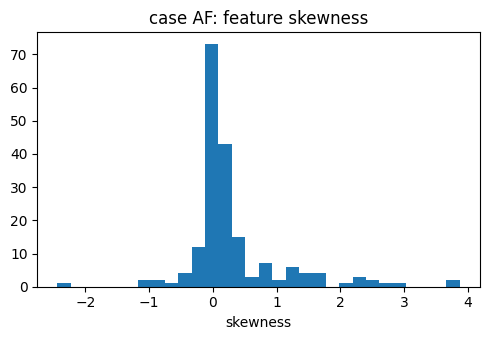

In [35]:
# This is a descriptive, full-training-set check only.
# During cross-validation, the actual zero-variance filter is refitted on Xtr
# separately inside each fold to avoid using validation data.
rows = []
for c in CASES:
    X = FEAT[c]
    variances = X.var(axis=0, ddof=0)
    n_zero = int((variances == 0).sum())
    rows.append({
        "case": c,
        "windows": len(X),
        "extracted_features": X.shape[1],
        "zero_variance_features": n_zero,
        "remaining_features": int((variances > 0).sum()),
        "zero_variance_share": f"{n_zero / X.shape[1]:.1%}"
    })
display(pd.DataFrame(rows).set_index("case"))

for c in CASES:
    zero_cols = FEAT[c].columns[FEAT[c].var(axis=0, ddof=0) == 0].tolist()
    print(f"{c}: zero-variance extracted features ({len(zero_cols)}):", zero_cols)

fig, ax = plt.subplots(1, len(CASES), figsize=(5 * len(CASES), 3.5), squeeze=False)
for a, c in zip(ax[0], CASES):
    sk = FEAT[c].skew().dropna()
    a.hist(sk, bins=30)
    a.set_title(f"case {c}: feature skewness")
    a.set_xlabel("skewness")
plt.tight_layout()
plt.show()


## 7. EDA 2: how does each feature relate to RUL?
**Spearman correlation** with RUL measures whether a feature moves steadily as RUL falls (+1 or -1 is a perfect steady relationship, 0 is none). The heat maps show every sensor and statistic for each case.

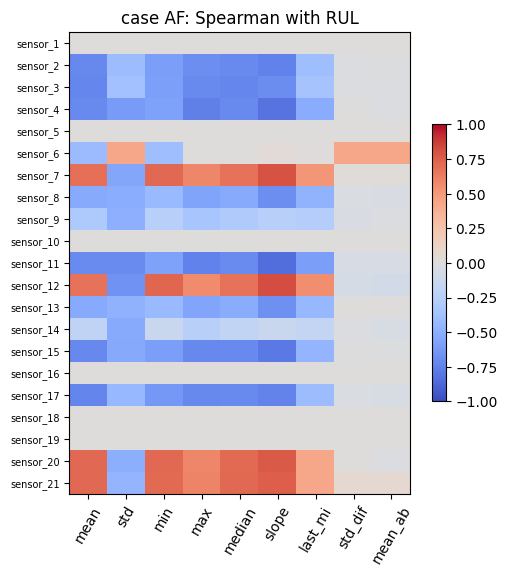

Average |Spearman| by statistic (higher = that kind of feature tracks RUL better):


,AF
mean,0.432
std,0.366
min,0.384
max,0.398
median,0.408
slope,0.455
last_minus_first,0.287
std_diff,0.036
mean_abs_diff,0.041


In [36]:
RHO = {c: FEAT[c].apply(lambda col: spearmanr(col.values, META[c].y.values)[0] if col.std() > 1e-8 else 0.0).fillna(0.0) for c in CASES}
fig, ax = plt.subplots(1, len(CASES), figsize=(5.5 * len(CASES), 6), squeeze=False)
for a, c in zip(ax[0], CASES):
    M = pd.DataFrame({st: [RHO[c][f"{s}__{st}"] for s in sensors] for st in STATS}, index=sensors)
    im = a.imshow(M.values, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1); a.grid(False)
    a.set_xticks(range(len(STATS))); a.set_xticklabels([s[:7] for s in STATS], rotation=60); a.set_yticks(range(len(sensors))); a.set_yticklabels(sensors, fontsize=7); a.set_title(f"case {c}: Spearman with RUL")
plt.colorbar(im, ax=ax[0], shrink=.6); plt.show()
print("Average |Spearman| by statistic (higher = that kind of feature tracks RUL better):")
display(pd.DataFrame({c: RHO[c].abs().groupby([n.split("__")[1] for n in RHO[c].index]).mean() for c in CASES}).reindex(STATS).round(3))

## 8. Feature ranking after zero-variance removal

For each training fold, we first remove every extracted feature whose variance is exactly zero in that fold's training windows. We then rank the remaining features using the same three methods:

1. **Absolute Spearman correlation** with RUL.
2. **Mutual information** with RUL.
3. **Random Forest impurity importance**.

Each method is converted to a percentile rank, and the three ranks are averaged. The top 60, 100 or 150 features are then evaluated. `ALL` means all non-zero-variance features, without a feature-count cap.

For this experiment, we do **not** apply the old 0.95 correlation-pruning step: it could return fewer than the requested 60, 100 or 150 features. The requested feature counts therefore remain interpretable. The zero-variance filter and feature ranking are fitted using training engines only inside each fold.


In [37]:
def rank_features(X, y):
    # Exact zero-variance filter: fit on the training partition only.
    variances = X.var(axis=0, ddof=0)
    X_nz = X.loc[:, variances > 0].copy()

    if X_nz.shape[1] == 0:
        raise ValueError("All extracted features have zero variance in this training fold.")

    y = np.asarray(y)
    rho = X_nz.apply(
        lambda col: abs(spearmanr(col.to_numpy(), y)[0])
    ).fillna(0.0)

    rows = np.random.default_rng(SEED).choice(
        len(X_nz), min(len(X_nz), MI_ROWS), replace=False
    )
    mi = pd.Series(
        mutual_info_regression(
            X_nz.to_numpy()[rows], y[rows],
            n_neighbors=3, random_state=SEED
        ),
        index=X_nz.columns
    )

    forest = RandomForestRegressor(
        n_estimators=SEL_TREES,
        min_samples_leaf=5,
        max_features=0.33,
        n_jobs=-1,
        random_state=SEED
    ).fit(X_nz.to_numpy(), y)

    imp = pd.Series(forest.feature_importances_, index=X_nz.columns)
    score = (
        rho.rank(pct=True) +
        mi.rank(pct=True) +
        imp.rank(pct=True)
    ) / 3

    ranking = pd.DataFrame({
        "variance": variances.loc[X_nz.columns],
        "spearman": rho,
        "mutual_info": mi,
        "rf_importance": imp,
        "score": score
    }).sort_values("score", ascending=False)

    return X_nz.columns.tolist(), ranking, int((variances == 0).sum())


def choose_features(X, y, budget):
    nonzero_features, ranking, n_zero = rank_features(X, y)

    if budget == "ALL":
        selected = nonzero_features
    else:
        selected = ranking.index[:min(int(budget), len(ranking))].tolist()

    return selected, ranking, n_zero


# Full-data ranking is for descriptive EDA/export only.
# CV model fitting below recomputes the ranking within each training fold.
RANKINGS = {}
for c in CASES:
    selected, RANKINGS[c], n_zero = choose_features(FEAT[c], META[c].y.values, "ALL")
    print(
        f"case {c}: {n_zero} zero-variance features removed; "
        f"{len(selected)} features remain"
    )
    print(f"case {c}: top 15 features by combined rank")
    display(RANKINGS[c].head(15).round(5))


case AF: 54 zero-variance features removed; 135 features remain
case AF: top 15 features by combined rank


,variance,spearman,mutual_info,rf_importance,score
sensor_11__slope,0.00011,0.83938,0.68678,0.26751,1.00000
sensor_4__slope,0.00011,0.81604,0.61720,0.08865,0.98519
sensor_12__slope,0.00011,0.81489,0.61281,0.11009,0.98272
sensor_7__slope,0.00011,0.80012,0.57020,0.11677,0.97778
sensor_4__max,0.64273,0.75210,0.64738,0.02283,0.96049
sensor_15__slope,0.00011,0.78658,0.53614,0.07017,0.95802
sensor_11__max,0.72965,0.74949,0.54429,0.03525,0.94815
sensor_21__slope,0.00011,0.75323,0.50288,0.02741,0.93580
sensor_20__slope,0.00010,0.77063,0.51369,0.01505,0.93086
sensor_15__max,0.59469,0.71648,0.56707,0.00529,0.89877


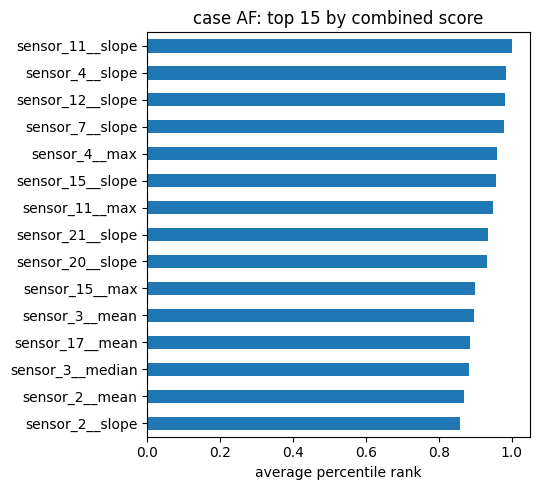

Feature-statistic counts among the top 150 (or all remaining features if fewer):


,AF
mean,15
std,15
min,15
max,15
median,15
slope,15
last_minus_first,15
std_diff,15
mean_abs_diff,15


Top sensors by number of features in the top 150:


,AF
sensor_11,9
sensor_4,9
sensor_12,9
sensor_7,9
sensor_15,9
sensor_21,9
sensor_20,9
sensor_3,9
sensor_17,9
sensor_2,9


In [38]:
fig, ax = plt.subplots(1, len(CASES), figsize=(5.5 * len(CASES), 5), squeeze=False)
for a, c in zip(ax[0], CASES):
    RANKINGS[c].head(15)["score"][::-1].plot.barh(ax=a)
    a.set_title(f"case {c}: top 15 by combined score")
    a.set_xlabel("average percentile rank")
plt.tight_layout()
plt.show()

print("Feature-statistic counts among the top 150 (or all remaining features if fewer):")
display(pd.DataFrame({
    c: pd.Series([f.split("__")[1] for f in RANKINGS[c].head(150).index]).value_counts()
    for c in CASES
}).reindex(STATS).fillna(0).astype(int))

print("Top sensors by number of features in the top 150:")
display(pd.DataFrame({
    c: pd.Series([f.split("__")[0] for f in RANKINGS[c].head(150).index]).value_counts()
    for c in CASES
}).fillna(0).astype(int))


## 9. Models and fixed hyperparameters

Only Random Forest and XGBoost are included, consistent with the current project scope. The model hyperparameters are held fixed across feature budgets so the experiment isolates the effect of feature-space size. Hyperparameter tuning should be conducted after this comparison.


In [39]:
def gpu_available():
    try:
        return subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0
    except Exception:
        return False

USE_GPU = gpu_available()
if QUICK:
    RF_TREES, XGB_TREES = 30, 60
else:
    RF_TREES, XGB_TREES = 150, 300

MODELS = {
    "RF": lambda: RandomForestRegressor(
        n_estimators=RF_TREES,
        min_samples_leaf=5,
        max_features=0.33,
        n_jobs=-1,
        random_state=SEED
    ),
    "XGB": lambda: XGBRegressor(
        n_estimators=XGB_TREES,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        device="cuda" if USE_GPU else "cpu",
        n_jobs=-1,
        random_state=SEED
    )
}

def make_folds(units, seed=SEED):
    # Same deterministic engine-wise fold assignment as the earlier notebook.
    u = np.array(sorted(units))
    rng = np.random.default_rng(seed)
    rng.shuffle(u)
    return {int(engine): i % N_FOLDS for i, engine in enumerate(u)}

print("RF trees:", RF_TREES, "| XGB trees:", XGB_TREES, "| GPU:", USE_GPU)


RF trees: 150 | XGB trees: 300 | GPU: False


## 10. Train, validate and test each feature budget

For every case and each of the five engine-wise folds:
1. Fit scaling using training engines only.
2. Extract training and validation windows using the same window settings as the previous notebook.
3. Remove zero-variance features using the training windows only.
4. Compute the combined feature ranking using training windows only.
5. Train RF and XGBoost separately with 60, 100, 150 and all remaining features.
6. Evaluate on the held-out validation engines.

Finally, refit the preprocessing and feature ranking on all training engines, then evaluate the official test set. The validation protocol remains the same as the previous notebook: all validation windows at cycles >= 50. The official test still uses one final window per test engine.


In [40]:
RESULTS = {}
FOLD_RESULTS = []
FINAL_FEATURES = {}
FINAL_RANKINGS = {}

def run_case(case):
    t0 = time.time()
    unit_arr = train.unit_id.values
    y_all = train.y.values

    fold_of = make_folds(units_all)
    fold_arr = np.array([fold_of[u] for u in units_all])

    for fold in range(N_FOLDS):
        tr_u = units_all[fold_arr != fold]
        va_u = units_all[fold_arr == fold]
        d_tr = train[np.isin(unit_arr, tr_u)]

        # Preprocessing is fitted only on the training engines of this fold.
        glob = Scaler(1).fit(d_tr)
        cond = Scaler(N_CONDITIONS).fit(d_tr)
        levels, changes = prepare(case, train, glob, cond)

        Xtr, r_tr = make_windows(
            levels, changes, tr_u, start=L, stride=TRAIN_STRIDE
        )
        Xva, r_va = make_windows(
            levels, changes, va_u, start=MIN_EVAL_CYCLE, stride=1
        )

        # Zero-variance filtering and ranking see training windows only.
        for budget in FEATURE_BUDGETS:
            keep, ranking, n_zero = choose_features(Xtr, y_all[r_tr], budget)

            for model_name, make_model in MODELS.items():
                model = make_model()
                model.fit(Xtr[keep].to_numpy(), y_all[r_tr])

                train_pred = np.clip(
                    model.predict(Xtr[keep].to_numpy()), 0, RUL_CAP
                )
                val_pred = np.clip(
                    model.predict(Xva[keep].to_numpy()), 0, RUL_CAP
                )

                FOLD_RESULTS.append({
                    "dataset": DATASET,
                    "case": case,
                    "budget": str(budget),
                    "model": model_name,
                    "fold": fold + 1,
                    "n_features": len(keep),
                    "zero_variance_removed": n_zero,
                    "train_rmse": rmse(y_all[r_tr], train_pred),
                    "val_rmse": rmse(y_all[r_va], val_pred)
                })

        print(
            f"[{DATASET} | {case}] fold {fold + 1}/{N_FOLDS} completed "
            f"({time.time() - t0:.0f}s)"
        )

    # Summarise the five validation folds.
    F = pd.DataFrame([
        row for row in FOLD_RESULTS
        if row["dataset"] == DATASET and row["case"] == case
    ])
    print(f"\n=== {DATASET} | case {case}: validation RMSE by fold ===")
    display(
        F.pivot_table(
            index="fold", columns=["budget", "model"], values="val_rmse"
        ).round(2)
    )

    # Final fit on all training engines, followed by official test evaluation.
    glob = Scaler(1).fit(train)
    cond = Scaler(N_CONDITIONS).fit(train)
    levels, changes = prepare(case, train, glob, cond)

    Xtr, r_tr = make_windows(
        levels, changes, units_all, start=L, stride=TRAIN_STRIDE
    )
    lev_te, chg_te = prepare(case, test, glob, cond)
    Xte = make_test_windows(lev_te, chg_te)

    for budget in FEATURE_BUDGETS:
        keep, ranking, n_zero = choose_features(Xtr, y_all[r_tr], budget)
        FINAL_FEATURES[(case, str(budget))] = keep
        FINAL_RANKINGS[(case, str(budget))] = ranking

        for model_name, make_model in MODELS.items():
            model = make_model()
            model.fit(Xtr[keep].to_numpy(), y_all[r_tr])
            test_pred = np.clip(
                model.predict(Xte[keep].to_numpy()), 0, RUL_CAP
            )

            fold_rows = F[
                (F["budget"] == str(budget)) &
                (F["model"] == model_name)
            ]

            RESULTS[(case, str(budget), model_name)] = {
                "dataset": DATASET,
                "case": case,
                "budget": str(budget),
                "model": model_name,
                "n_features": len(keep),
                "zero_variance_removed": n_zero,
                "val_rmse_mean": fold_rows["val_rmse"].mean(),
                "val_rmse_sd": fold_rows["val_rmse"].std(),
                "test_rmse": rmse(y_test, test_pred),
                "test_nasa_score": nasa_score(y_test, test_pred)
            }

    result_table = pd.DataFrame([
        RESULTS[(case, str(b), m)]
        for b in FEATURE_BUDGETS for m in MODELS
    ])
    print(f"\n=== {DATASET} | case {case}: final results ===")
    display(
        result_table.set_index(["budget", "model"])[
            ["n_features", "val_rmse_mean", "val_rmse_sd",
             "test_rmse", "test_nasa_score"]
        ].round(3)
    )
    print(f"case {case} finished in {(time.time() - t0) / 60:.1f} min")


## 11. Save and compare results

The `ALL` condition is the baseline using every feature that survives zero-variance removal. Compare the 60, 100 and 150 feature settings against this baseline. Because zero-variance filtering is performed inside each fold, the number of remaining features can vary slightly between folds.

The old hard-coded Q1/Q2 reference values are intentionally not reused: those results were produced with a different feature-selection/evaluation setup. The `ALL` run in this notebook is the fair within-experiment baseline.


In [41]:
# Run all requested cases.
for case in CASES:
    run_case(case)

SUMMARY = pd.DataFrame(RESULTS.values()).sort_values(
    ["case", "model", "budget"]
).reset_index(drop=True)

FOLD_SUMMARY = pd.DataFrame(FOLD_RESULTS)

display(SUMMARY.round(3))

summary_path = f"{OUT_DIR}/feature_selection_summary_{DATASET}.csv"
fold_path = f"{OUT_DIR}/feature_selection_folds_{DATASET}.csv"
ranking_path = f"{OUT_DIR}/feature_ranking_{DATASET}.csv"

SUMMARY.to_csv(summary_path, index=False)
FOLD_SUMMARY.to_csv(fold_path, index=False)

ranking_frames = []
for (case, budget), ranking in FINAL_RANKINGS.items():
    temp = ranking.copy()
    temp["case"] = case
    temp["budget"] = budget
    temp["selected"] = temp.index.isin(FINAL_FEATURES[(case, budget)])
    ranking_frames.append(temp.rename_axis("feature").reset_index())

pd.concat(ranking_frames, ignore_index=True).to_csv(ranking_path, index=False)

print("Saved:")
print(summary_path)
print(fold_path)
print(ranking_path)


[FD001 | AF] fold 1/5 completed (73s)
[FD001 | AF] fold 2/5 completed (145s)
[FD001 | AF] fold 3/5 completed (220s)
[FD001 | AF] fold 4/5 completed (294s)
[FD001 | AF] fold 5/5 completed (366s)

=== FD001 | case AF: validation RMSE by fold ===


budget    100           150            20            40            60           ALL       
model      RF    XGB     RF    XGB     RF    XGB     RF    XGB     RF    XGB     RF    XGB
fold                                                                                      
1       12.00  11.83  12.12  11.74  13.49  13.40  13.58  13.44  12.00  11.90  12.07  11.90
2       11.61  11.02  11.58  11.22  14.10  14.15  14.24  13.92  11.45  11.15  11.64  11.15
3       11.33  11.01  11.49  11.29  12.74  12.98  11.47  11.45  11.11  11.08  11.46  11.17
4       11.19  11.25  11.37  11.53  12.48  13.55  11.42  11.50  10.99  11.22  11.38  11.28
5       10.40  10.48  10.46  10.56  14.31  14.35  14.28  14.20  10.31  10.46  10.50  10.60


=== FD001 | case AF: final results ===


n_features  val_rmse_mean  val_rmse_sd  test_rmse  test_nasa_score
budget model                                                                    
20     RF             20         13.424        0.806     14.634          334.470
       XGB            20         13.686        0.559     15.368          408.155
40     RF             40         12.998        1.445     14.605          310.841
       XGB            40         12.902        1.331     14.725          332.905
60     RF             60         11.172        0.622     12.844          258.305
       XGB            60         11.160        0.512     13.043          281.458
100    RF            100         11.306        0.595     12.789          250.747
       XGB           100         11.118        0.489     13.099          258.569
150    RF            135         11.406        0.601     12.982          263.057
       XGB           135         11.271        0.445     13.095          266.987
ALL    RF            135         11.411        0.573     12.961          256.863
       XGB           135         11.218        0.462     12.973          255.653

case AF finished in 7.6 min


,dataset,case,budget,model,n_features,zero_variance_removed,val_rmse_mean,val_rmse_sd,test_rmse,test_nasa_score
0,FD001,AF,100,RF,100,54,11.306,0.595,12.789,250.747
1,FD001,AF,150,RF,135,54,11.406,0.601,12.982,263.057
2,FD001,AF,20,RF,20,54,13.424,0.806,14.634,334.470
3,FD001,AF,40,RF,40,54,12.998,1.445,14.605,310.841
4,FD001,AF,60,RF,60,54,11.172,0.622,12.844,258.305
5,FD001,AF,ALL,RF,135,54,11.411,0.573,12.961,256.863
6,FD001,AF,100,XGB,100,54,11.118,0.489,13.099,258.569
7,FD001,AF,150,XGB,135,54,11.271,0.445,13.095,266.987
8,FD001,AF,20,XGB,20,54,13.686,0.559,15.368,408.155
9,FD001,AF,40,XGB,40,54,12.902,1.331,14.725,332.905


Saved:
/kaggle/working/feature_selection_summary_FD001.csv
/kaggle/working/feature_selection_folds_FD001.csv
/kaggle/working/feature_ranking_FD001.csv


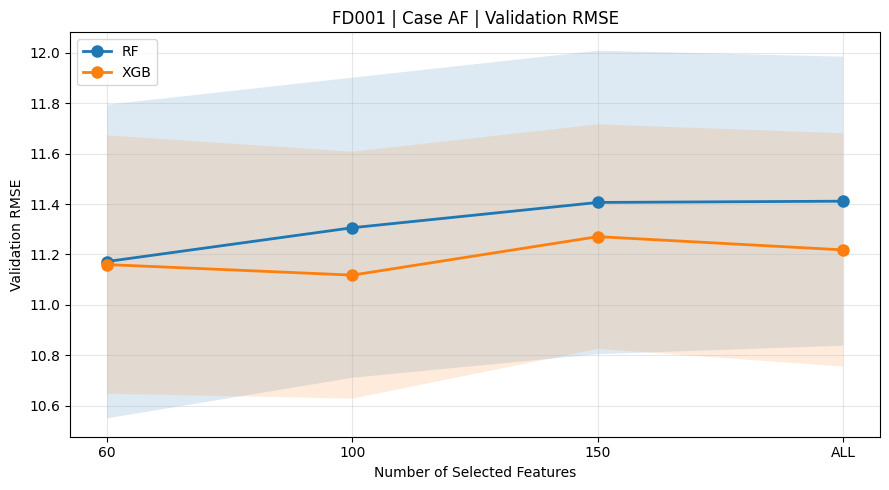

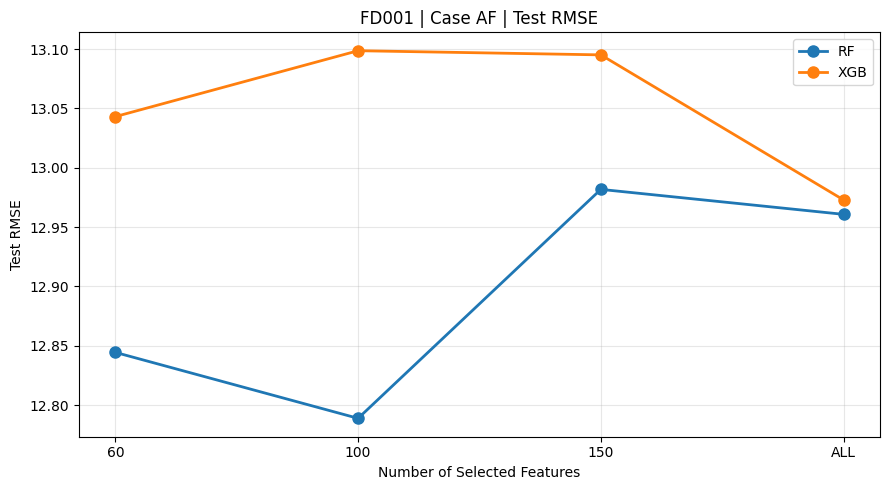

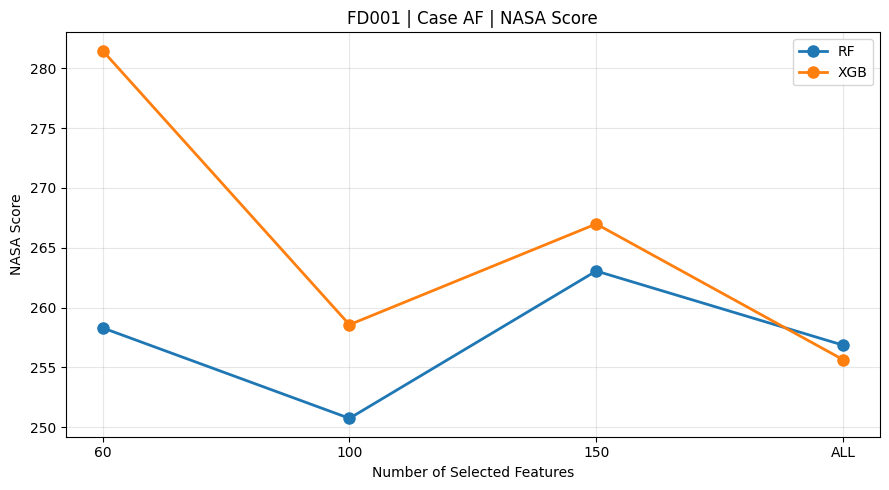

In [42]:
# ============================================================
# FD001: FEATURE BUDGET COMPARISON
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "/kaggle/working/feature_selection_summary_FD001.csv"
)

budgets = ["60", "100", "150", "ALL"]
models = ["RF", "XGB"]
cases = sorted(df["case"].unique())

metrics = [
    ("val_rmse_mean", "val_rmse_sd", "Validation RMSE"),
    ("test_rmse", None, "Test RMSE"),
    ("test_nasa_score", None, "NASA Score")
]

for case in cases:

    case_df = df[df["case"] == case]

    for metric, error, title in metrics:

        fig, ax = plt.subplots(figsize=(9, 5))

        for model in models:

            data = (
                case_df[case_df["model"] == model]
                .set_index("budget")
                .reindex(budgets)
            )

            y = data[metric].values
            x = np.arange(len(budgets))

            ax.plot(
                x, y,
                marker="o",
                linewidth=2,
                markersize=8,
                label=model
            )

            if error is not None:
                sd = data[error].values
                ax.fill_between(
                    x, y - sd, y + sd,
                    alpha=0.15
                )

        ax.set_xticks(range(len(budgets)))
        ax.set_xticklabels(budgets)

        ax.set_xlabel("Number of Selected Features")
        ax.set_ylabel(title)
        ax.set_title(f"FD001 | Case {case} | {title}")

        ax.grid(alpha=0.3)
        ax.legend()
        plt.tight_layout()
        plt.show()